In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, GRU, Input
from tensorflow.keras.utils import to_categorical


In [11]:
DATA_DIR = "./UCI HAR Dataset/UCI HAR Dataset"

def load_signals(split):
    signals = []
    sensors = ['body_acc', 'body_gyro']
    axes = ['x', 'y', 'z']

    for sensor in sensors:
        for axis in axes:
            path = f"{DATA_DIR}/{split}/Inertial Signals/{sensor}_{axis}_{split}.txt"
            data = pd.read_csv(path, sep='\s+', header=None)
            signals.append(data.values)

    return np.stack(signals, axis=2)

X_train = load_signals("train")
X_test  = load_signals("test")

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (7352, 128, 6)
Test shape: (2947, 128, 6)


In [12]:
y_train = pd.read_csv(f"{DATA_DIR}/train/y_train.txt", header=None)[0]
y_test  = pd.read_csv(f"{DATA_DIR}/test/y_test.txt", header=None)[0]

encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test  = encoder.transform(y_test)

y_train = to_categorical(y_train)
y_test  = to_categorical(y_test)

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]
print("Activity classes:", encoder.classes_)


Activity classes: [1 2 3 4 5 6]


In [13]:
def build_rnn():
    model = Sequential([
        Input(shape=(128, 6)),
        SimpleRNN(64),
        Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

rnn_model = build_rnn()
history_rnn = rnn_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    verbose=1
)


Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.2452 - loss: 1.6883 - val_accuracy: 0.2570 - val_loss: 1.5783
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.2792 - loss: 1.5540 - val_accuracy: 0.2515 - val_loss: 1.4820
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.3008 - loss: 1.4489 - val_accuracy: 0.3263 - val_loss: 1.3904
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.3056 - loss: 1.6356 - val_accuracy: 0.2896 - val_loss: 1.7553
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.3307 - loss: 1.4164 - val_accuracy: 0.3644 - val_loss: 1.2474
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.2331 - loss: 1.8054 - val_accuracy: 0.1312 - val_loss: 1.8082
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.2433 - loss: 1.6730 - val_accuracy: 0.2896 - val_loss: 1.5550
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.2707 - loss: 1.6116 - val_accuracy: 0.2291 - v

In [14]:
def build_lstm():
    model = Sequential([
        Input(shape=(128, 6)),
        LSTM(64),
        Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

lstm_model = build_lstm()
history_lstm = lstm_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    verbose=1
)


Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 95ms/step - accuracy: 0.3112 - loss: 1.5463 - val_accuracy: 0.3487 - val_loss: 1.3552
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.3618 - loss: 1.3473 - val_accuracy: 0.3827 - val_loss: 1.2198
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.4069 - loss: 1.1881 - val_accuracy: 0.4194 - val_loss: 1.1051
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.4246 - loss: 1.1171 - val_accuracy: 0.4215 - val_loss: 1.0499
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 88ms/step - accuracy: 0.3763 - loss: 1.1608 - val_accuracy: 0.3821 - val_loss: 1.1095
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.3703 - loss: 1.3151 - val_accuracy: 0.3766 - val_loss: 1.1426
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.3868 - loss: 1.1440 - val_accuracy: 0.3984 - val_loss: 1.1091
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.4305 - loss: 1.0886 - val_accuracy: 0.4507 - 

In [15]:
def build_gru():
    model = Sequential([
        Input(shape=(128, 6)),
        GRU(64),
        Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

gru_model = build_gru()
history_gru = gru_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    verbose=1
)


Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - accuracy: 0.2262 - loss: 1.7735 - val_accuracy: 0.2787 - val_loss: 1.6806
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 99ms/step - accuracy: 0.3532 - loss: 1.2677 - val_accuracy: 0.3562 - val_loss: 1.5087
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.3634 - loss: 1.3894 - val_accuracy: 0.3950 - val_loss: 1.1305
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.4076 - loss: 1.1306 - val_accuracy: 0.4004 - val_loss: 1.1105
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step - accuracy: 0.4234 - loss: 1.1013 - val_accuracy: 0.4011 - val_loss: 1.0903
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.4533 - loss: 1.0669 - val_accuracy: 0.4426 - val_loss: 1.0560
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.4623 - loss: 0.9991 - val_accuracy: 0.4657 - val_loss: 0.9694
Epoch 8/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step - accuracy: 0.5003 - loss: 0.9304 - val_accuracy: 0.5037 -

In [17]:
def evaluate_model(model, name):
    y_pred = np.argmax(model.predict(X_test), axis=1)
    y_true = np.argmax(y_test, axis=1)

    print(f"\n{name} Results")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred, average="weighted"))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print("\nClassification Report:\n",
          classification_report(y_true, y_pred, target_names=activity_names))



In [18]:
evaluate_model(rnn_model, "Simple RNN")
evaluate_model(lstm_model, "LSTM")
evaluate_model(gru_model, "GRU")


93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step   

Simple RNN Results
Accuracy: 0.3193077706141839
F1 Score: 0.2708964475251978
Confusion Matrix:
 [[271  62  84  14  24  41]
 [231  69  90  16  21  44]
 [193  63 113   3  18  30]
 [ 27   0   1  31 390  42]
 [ 20   1   1  48 408  54]
 [ 32   0   8  74 374  49]]

Classification Report:
                     precision    recall  f1-score   support

           WALKING       0.35      0.55      0.43       496
  WALKING_UPSTAIRS       0.35      0.15      0.21       471
WALKING_DOWNSTAIRS       0.38      0.27      0.32       420
           SITTING       0.17      0.06      0.09       491
          STANDING       0.33      0.77      0.46       532
            LAYING       0.19      0.09      0.12       537

          accuracy                           0.32      2947
         macro avg       0.29      0.31      0.27      2947
      weighted avg       0.29      0.32      0.27      2947

93/93 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step

LSTM Results
Accuracy: 0.606

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


93/93 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step

GRU Results
Accuracy: 0.5982354937224296
F1 Score: 0.5549170664084508
Confusion Matrix:
 [[450  16  30   0   0   0]
 [  8 460   3   0   0   0]
 [ 19  36 361   1   0   3]
 [  0   1   0  67 419   4]
 [  0   3   0 106 405  18]
 [  1   0   0  59 457  20]]

Classification Report:
                     precision    recall  f1-score   support

           WALKING       0.94      0.91      0.92       496
  WALKING_UPSTAIRS       0.89      0.98      0.93       471
WALKING_DOWNSTAIRS       0.92      0.86      0.89       420
           SITTING       0.29      0.14      0.19       491
          STANDING       0.32      0.76      0.45       532
            LAYING       0.44      0.04      0.07       537

          accuracy                           0.60      2947
         macro avg       0.63      0.61      0.57      2947
      weighted avg       0.62      0.60      0.55      2947



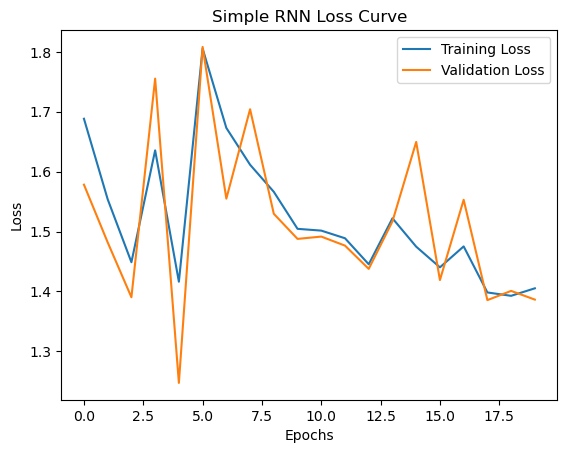

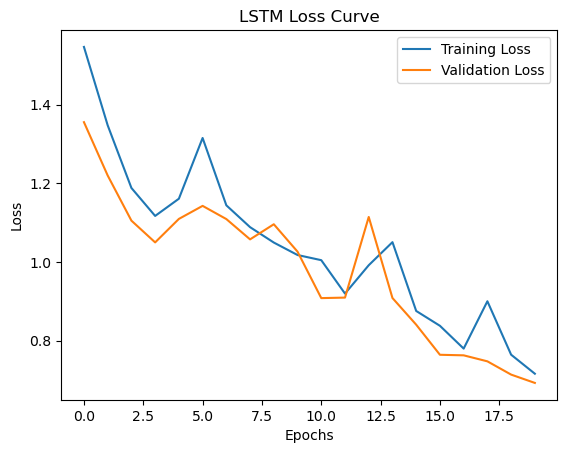

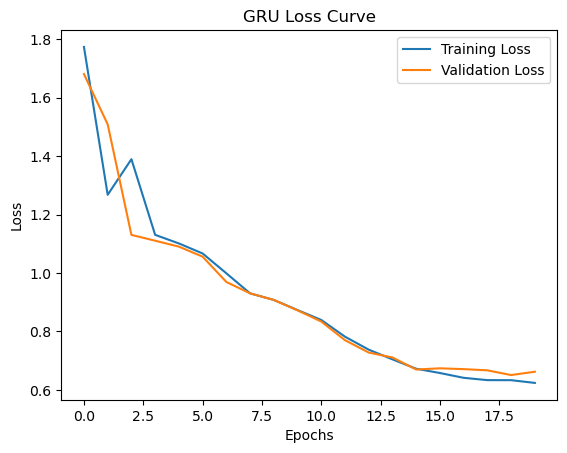

In [19]:
def plot_loss(history, title):
    plt.figure()
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(title)
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

plot_loss(history_rnn, "Simple RNN Loss Curve")
plot_loss(history_lstm, "LSTM Loss Curve")
plot_loss(history_gru, "GRU Loss Curve")
